In [17]:
import math
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import DataLoader, Subset, ConcatDataset

from torchvision import datasets, transforms

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from IPython.display import clear_output

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

T = 1000
beta = torch.linspace(1e-4, 0.02, T).to(device)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)


In [19]:
class TimeEmbed(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(1, dim),
            nn.SiLU(),
            nn.Linear(dim, dim)
        )

    def forward(self, t):
        return self.mlp(t[:, None])

class EncDec(nn.Module):
    def __init__(self, in_ch=3, latent_ch=64, base=32):
        super().__init__()
        self.time = TimeEmbed(latent_ch)
        self.enc = nn.Sequential(
            nn.Conv2d(in_ch, base, 4, stride=2, padding=1),      # 32->16
            nn.ReLU(),
            nn.Conv2d(base, base, 3, stride=1, padding=1),       # 16->16
            nn.ReLU(),
            nn.Conv2d(base, base, 3, stride=2, padding=1),       # 16->6
            nn.ReLU(),
            nn.Conv2d(base, latent_ch, 3, stride=1, padding=1),  # 8->8
        )
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(latent_ch, base, 3, stride=2, padding=0),
            nn.ReLU(),
            nn.ConvTranspose2d(base, base, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(base, in_ch, 2, stride=1, padding=1),
        )
    
    def forward(self, x, t):
        z = self.enc(x)
        t_emb = self.time(t)
        z = z + t_emb[:, :, None, None]
        x_hat = self.dec(z)
        return x_hat, z

class Block(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_emb = nn.Linear(t_dim, out_ch)

    def forward(self, x, t):
        h = F.silu(self.conv1(x))
        h = h + self.time_emb(t)[:, :, None, None]
        h = F.silu(self.conv2(h))
        return h

class StandardClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        base = 32
        t_dim = 32

        self.time_embed = TimeEmbed(t_dim)

        self.down1 = Block(3, base, t_dim)
        self.down2 = Block(base, base * 2, t_dim)
        self.down3 = Block(base * 2, base * 2, t_dim)
        self.pool = nn.MaxPool2d(2)

        self.mid = Block(base * 2, base * 2, t_dim)

        self.out = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(base * 2, 2)
        )
        
    def forward(self, x, t):
        t = self.time_embed(t)

        d1 = self.down1(x, t)
        d2 = self.down2(self.pool(d1), t)
        d3 = self.down3(self.pool(d2), t)

        m = self.mid(d3, t)

        return self.out(m)


import math
import torch
from torch import nn
from torch.nn import init
from torch.nn import functional as F


class Swish(nn.Module):
    def forward(self, x):
        return x * torch.sigmoid(x)


class TimeEmbedding(nn.Module):
    def __init__(self, T, d_model, dim):
        assert d_model % 2 == 0
        super().__init__()
        emb = torch.arange(0, d_model, step=2) / d_model * math.log(10000)
        emb = torch.exp(-emb)
        pos = torch.arange(T).float()
        emb = pos[:, None] * emb[None, :]
        assert list(emb.shape) == [T, d_model // 2]
        emb = torch.stack([torch.sin(emb), torch.cos(emb)], dim=-1)
        assert list(emb.shape) == [T, d_model // 2, 2]
        emb = emb.view(T, d_model)

        self.timembedding = nn.Sequential(
            nn.Embedding.from_pretrained(emb),
            nn.Linear(d_model, dim),
            Swish(),
            nn.Linear(dim, dim),
        )
        self.initialize()

    def initialize(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                init.xavier_uniform_(module.weight)
                init.zeros_(module.bias)

    def forward(self, t):
        emb = self.timembedding(t)
        return emb


class DownSample(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.main = nn.Conv2d(in_ch, in_ch, 3, stride=2, padding=1)
        self.initialize()

    def initialize(self):
        init.xavier_uniform_(self.main.weight)
        init.zeros_(self.main.bias)

    def forward(self, x, temb):
        x = self.main(x)
        return x


class UpSample(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.main = nn.Conv2d(in_ch, in_ch, 3, stride=1, padding=1)
        self.initialize()

    def initialize(self):
        init.xavier_uniform_(self.main.weight)
        init.zeros_(self.main.bias)

    def forward(self, x, temb):
        _, _, H, W = x.shape
        x = F.interpolate(
            x, scale_factor=2, mode='nearest')
        x = self.main(x)
        return x


class AttnBlock(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.group_norm = nn.GroupNorm(32, in_ch)
        self.proj_q = nn.Conv2d(in_ch, in_ch, 1, stride=1, padding=0)
        self.proj_k = nn.Conv2d(in_ch, in_ch, 1, stride=1, padding=0)
        self.proj_v = nn.Conv2d(in_ch, in_ch, 1, stride=1, padding=0)
        self.proj = nn.Conv2d(in_ch, in_ch, 1, stride=1, padding=0)
        self.initialize()

    def initialize(self):
        for module in [self.proj_q, self.proj_k, self.proj_v, self.proj]:
            init.xavier_uniform_(module.weight)
            init.zeros_(module.bias)
        init.xavier_uniform_(self.proj.weight, gain=1e-5)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.group_norm(x)
        q = self.proj_q(h)
        k = self.proj_k(h)
        v = self.proj_v(h)

        q = q.permute(0, 2, 3, 1).view(B, H * W, C)
        k = k.view(B, C, H * W)
        w = torch.bmm(q, k) * (int(C) ** (-0.5))
        assert list(w.shape) == [B, H * W, H * W]
        w = F.softmax(w, dim=-1)

        v = v.permute(0, 2, 3, 1).view(B, H * W, C)
        h = torch.bmm(w, v)
        assert list(h.shape) == [B, H * W, C]
        h = h.view(B, H, W, C).permute(0, 3, 1, 2)
        h = self.proj(h)

        return x + h


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, tdim, dropout, attn=False):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.GroupNorm(32, in_ch),
            Swish(),
            nn.Conv2d(in_ch, out_ch, 3, stride=1, padding=1),
        )
        self.temb_proj = nn.Sequential(
            Swish(),
            nn.Linear(tdim, out_ch),
        )
        self.block2 = nn.Sequential(
            nn.GroupNorm(32, out_ch),
            Swish(),
            nn.Dropout(dropout),
            nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1),
        )
        if in_ch != out_ch:
            self.shortcut = nn.Conv2d(in_ch, out_ch, 1, stride=1, padding=0)
        else:
            self.shortcut = nn.Identity()
        if attn:
            self.attn = AttnBlock(out_ch)
        else:
            self.attn = nn.Identity()
        self.initialize()

    def initialize(self):
        for module in self.modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                init.xavier_uniform_(module.weight)
                init.zeros_(module.bias)
        init.xavier_uniform_(self.block2[-1].weight, gain=1e-5)

    def forward(self, x, temb):
        h = self.block1(x)
        h += self.temb_proj(temb)[:, :, None, None]
        h = self.block2(h)

        h = h + self.shortcut(x)
        h = self.attn(h)
        return h


class UNet(nn.Module):
    def __init__(self, T, ch, ch_mult, attn, num_res_blocks, dropout):
        super().__init__()
        assert all([i < len(ch_mult) for i in attn]), 'attn index out of bound'
        tdim = ch * 4
        self.time_embedding = TimeEmbedding(T, ch, tdim)

        self.head = nn.Conv2d(3, ch, kernel_size=3, stride=1, padding=1)
        self.downblocks = nn.ModuleList()
        chs = [ch]  # record output channel when dowmsample for upsample
        now_ch = ch
        for i, mult in enumerate(ch_mult):
            out_ch = ch * mult
            for _ in range(num_res_blocks):
                self.downblocks.append(ResBlock(
                    in_ch=now_ch, out_ch=out_ch, tdim=tdim,
                    dropout=dropout, attn=(i in attn)))
                now_ch = out_ch
                chs.append(now_ch)
            if i != len(ch_mult) - 1:
                self.downblocks.append(DownSample(now_ch))
                chs.append(now_ch)

        self.middleblocks = nn.ModuleList([
            ResBlock(now_ch, now_ch, tdim, dropout, attn=True),
            ResBlock(now_ch, now_ch, tdim, dropout, attn=False),
        ])

        self.upblocks = nn.ModuleList()
        for i, mult in reversed(list(enumerate(ch_mult))):
            out_ch = ch * mult
            for _ in range(num_res_blocks + 1):
                self.upblocks.append(ResBlock(
                    in_ch=chs.pop() + now_ch, out_ch=out_ch, tdim=tdim,
                    dropout=dropout, attn=(i in attn)))
                now_ch = out_ch
            if i != 0:
                self.upblocks.append(UpSample(now_ch))
        assert len(chs) == 0

        self.tail = nn.Sequential(
            nn.GroupNorm(32, now_ch),
            Swish(),
            nn.Conv2d(now_ch, 3, 3, stride=1, padding=1)
        )
        self.initialize()

    def initialize(self):
        init.xavier_uniform_(self.head.weight)
        init.zeros_(self.head.bias)
        init.xavier_uniform_(self.tail[-1].weight, gain=1e-5)
        init.zeros_(self.tail[-1].bias)

    def forward(self, x, t):
        # Timestep embedding
        temb = self.time_embedding(t)
        # Downsampling
        h = self.head(x)
        hs = [h]
        for layer in self.downblocks:
            h = layer(h, temb)
            hs.append(h)
        # Middle
        for layer in self.middleblocks:
            h = layer(h, temb)
        # Upsampling
        for layer in self.upblocks:
            if isinstance(layer, ResBlock):
                h = torch.cat([h, hs.pop()], dim=1)
            h = layer(h, temb)
        h = self.tail(h)

        assert len(hs) == 0
        return h


class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [20]:
img_size = 32
timesteps = 1000

standardClassifier = StandardClassifier().to(device)
uNet = UNet(T=timesteps, ch=128, ch_mult=[1, 2, 2, 2], attn=[1], num_res_blocks=2, dropout=0.1).to(device)

file_location = r"ckpt.pt"
checkpoint = torch.load(file_location, map_location="cuda", weights_only=True)

uNet.load_state_dict(checkpoint['ema_model'])
standardClassifier.load_state_dict(torch.load("standardClassifier.pth", map_location=device, weights_only=False))

uNet.eval()
standardClassifier.eval()

cls = Classifier().cuda()
cls.load_state_dict(torch.load("cifar10_cnn_wei.pth"))
cls.eval()

1

1

In [21]:
# n_samples = 3

# with torch.no_grad():
#     xt = torch.randn(n_samples, 3, img_size, img_size).to(device)
    
#     for i in reversed(range(timesteps)):
#         # print(i)
#         t = torch.tensor([i] * n_samples, device=device)
        
#         eps_pred = uNet(xt, t.long())
        
#         alpha_t = alpha[i]
#         alpha_bar_t = alpha_bar[i]
#         beta_t = beta[i]

#         mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

#         with torch.enable_grad():
#             dre_xt = xt.detach().clone().requires_grad_(True)
            
#             logits = standardClassifier(dre_xt, t/1000)
#             log_probs = F.log_softmax(logits, dim=1)
            
#             r = log_probs[:, 1] - log_probs[:, 0]
            
#             guide_score = torch.autograd.grad(
#                 outputs=r.sum(),
#                 inputs=dre_xt
#             )[0]
            
#         mean = mean + 1 * beta_t * guide_score
        
#         if i > 0:
#             noise = torch.randn_like(xt)
#             xt = mean + torch.sqrt(beta_t) * noise
#         else:
#             xt = mean


In [22]:
# n_samples = 100
# s = 0
# final = []
# s_values = [0, 0.5, 1, 1.5, 2, 2.5]

# for i in range(5):
    
#     final_outputs = []
#     for s in s_values:
#         with torch.no_grad():
#             xt = torch.randn(n_samples, 3, img_size, img_size).to(device)
            
#             for i in reversed(range(timesteps)):
#                 # print(i)
#                 t = torch.tensor([i] * n_samples, device=device)
                
#                 eps_pred = uNet(xt, t.long())
                
#                 alpha_t = alpha[i]
#                 alpha_bar_t = alpha_bar[i]
#                 beta_t = beta[i]
        
#                 mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)
        
#                 with torch.enable_grad():
#                     dre_xt = xt.detach().clone().requires_grad_(True)
                    
#                     logits = standardClassifier(dre_xt, t/1000)
#                     log_probs = F.log_softmax(logits, dim=1)
                    
#                     r = log_probs[:, 1] - log_probs[:, 0]
                    
#                     guide_score = torch.autograd.grad(
#                         outputs=r.sum(),
#                         inputs=dre_xt
#                     )[0]
                    
#                 mean = mean + s * beta_t * guide_score
                
#                 if i > 0:
#                     noise = torch.randn_like(xt)
#                     xt = mean + torch.sqrt(beta_t) * noise
#                 else:
#                     xt = mean
#         print("s: {} complete", s)
#         final_outputs.append((s, xt.cpu()))
#     final.append(final_outputs)

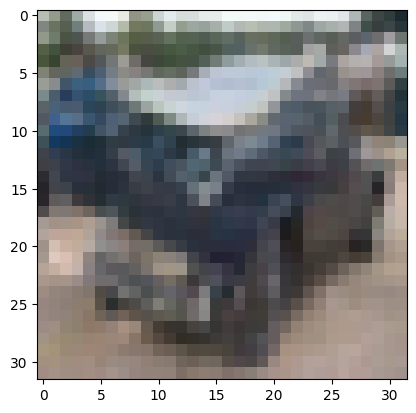

In [23]:
# torch.save(final, "5_runs_of_100_samples_of_5_guidance_strengths.pt")
final = torch.load("5_runs_of_100_samples_of_5_guidance_strengths.pt")

test_image = final[0][0][1][3].permute(1,2,0).cpu()*0.5+0.5
plt.imshow(test_image)

# print(cls(test_image[None, None, :, :].cuda()).argmax().cpu().item())

In [24]:
from datasets import load_dataset
from torch.utils.data import DataLoader
import torch
from torchvision import transforms

dataset = load_dataset("cifar10")

In [25]:
transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

In [26]:
real_images = torch.stack([transform(a['img']) for a in dataset['test'] if a['label'] in {2,3,4,5,6,7}])
real_images.mean()

tensor(-0.0934)

In [27]:
def knn_radius(features, k=3):
    dists = torch.cdist(features, features)
    dists.fill_diagonal_(float("inf"))
    return dists.kthvalue(k, dim=1).values


def precision(real_feats, fake_feats, r_real):
    d = torch.cdist(fake_feats, real_feats)
    return (d <= r_real.unsqueeze(0)).any(dim=1).float().mean().item()


def recall(real_feats, fake_feats, r_fake):
    d = torch.cdist(real_feats, fake_feats)
    return (d <= r_fake.unsqueeze(0)).any(dim=1).float().mean().item()

In [28]:
experiments = []
cls.eval()
for experiment in final:
    metrics = []
    perm = torch.randperm(real_images.shape[0])[:100]
    for s, fake_images in experiment:
        real_feats = cls.features(real_images[perm].cuda())
        fake_feats = cls.features(fake_images.cuda())
        
        r_real = knn_radius(real_feats)
        r_fake = knn_radius(fake_feats)
        
        p = precision(real_feats, fake_feats, r_real)
        r = recall(real_feats, fake_feats, r_fake)
    
        # print(f"Guidance: {s}, Precision: {p:.4f}, Recall: {r:.4f}")
        metrics.append((s, p, r, (2 * p * r) / (p + r)))
    experiments.append(metrics)

In [29]:
# torch.save(experiments, "5_runs_of_100_samples_of_5_guidance_strengths_after_cls_gets_features.pt")
experiments = torch.load("5_runs_of_100_samples_of_5_guidance_strengths_after_cls_gets_features.pt")

In [43]:
steps = torch.tensor(experiments)[0,:,0]
values = torch.tensor(experiments)[:,:,1:]
n = values.shape[0]
mean_exp = values.mean(dim=0)
std_exp = values.std(dim=0, unbiased=True)
sem_exp = std_exp / (n ** 0.5) * 2.132

steps, mean_exp[:,0], sem_exp[:,0]

(tensor([0.0000, 0.5000, 1.0000, 1.5000, 2.0000, 2.5000]),
 tensor([0.7060, 0.8180, 0.8960, 0.9320, 0.9360, 0.9540]),
 tensor([0.1095, 0.0297, 0.0283, 0.0401, 0.0348, 0.0313]))

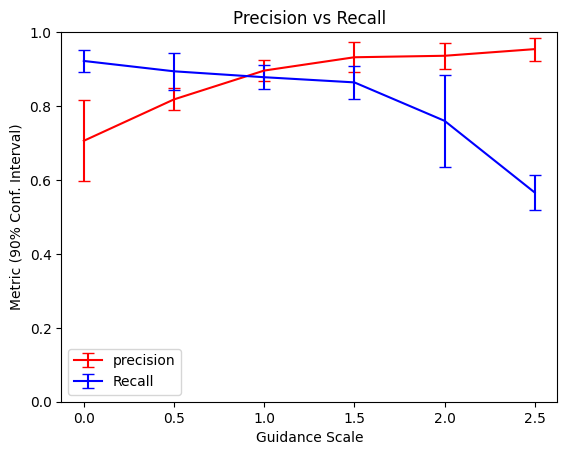

In [44]:
plt.ylim(0,1)
plt.errorbar(steps, mean_exp[:,0], yerr=sem_exp[:,0], capsize=4, color="red", label="precision")
plt.errorbar(steps, mean_exp[:,1], yerr=sem_exp[:,1], capsize=4, color="blue", label="Recall")
plt.title("Precision vs Recall")
plt.ylabel("Metric (90% Conf. Interval)")
plt.xlabel("Guidance Scale")
plt.legend()

<ErrorbarContainer object of 3 artists>

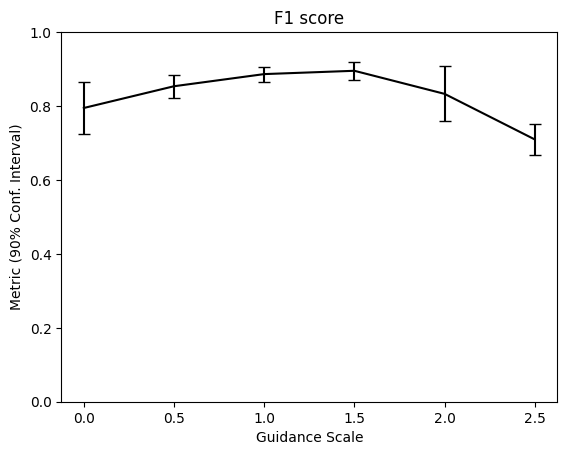

In [47]:
plt.ylim(0,1)
plt.title("F1 score")
plt.ylabel("Metric (90% Conf. Interval)")
plt.xlabel("Guidance Scale")
plt.errorbar(steps, mean_exp[:,2], yerr=sem_exp[:,2], capsize=4, color="black")


In [10]:
experiments[0]

[(0, 0.85999995470047, 0.9300000071525574, 0.8936312637623461),
 (0.5, 0.8499999642372131, 0.9099999666213989, 0.878977238035122),
 (1, 0.9399999976158142, 0.8799999952316284, 0.909010985352224),
 (1.5, 0.949999988079071, 0.8799999952316284, 0.9136611941025276),
 (2, 0.9799999594688416, 0.8299999833106995, 0.8987845035558625),
 (2.5, 0.9599999785423279, 0.6200000047683716, 0.7534177184315028)]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.030124664..1.0515635].


(-0.5, 639.5, 191.5, -0.5)

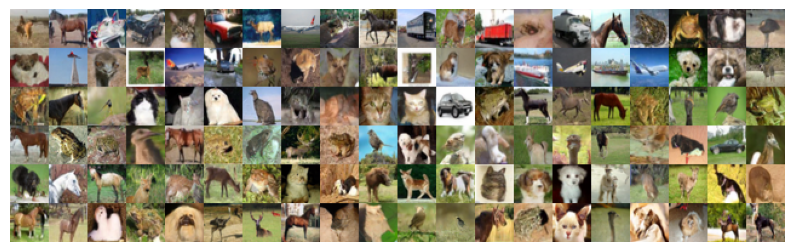

In [46]:
img = torch.tensor([])
experiments = []
cls.eval()
for experiment in final[:1]:
    metrics = []
    for s, fake_images in experiment:
        row = torch.cat([fake_images[i].permute(1,2,0) * 0.5 + 0.5 for i in range(20)], dim=1)
        img = torch.cat([img, row], dim = 0)

plt.figure(frameon=False, figsize=(10,10))
plt.imshow(img)
plt.axis('off')